# Proyecto ML — Visión Artificial · **Entrega 2**
## BreastMNIST: Estudio comparativo CNN vs Transformer en dos resoluciones
### CINF104 — Universidad Andrés Bello | 2026

| Campo | Valor |
|---|---|
| Dataset | BreastMNIST (MedMNIST v2) — 780 ecografías de mama |
| Tarea | Clasificación binaria: Maligno (0) vs Normal/Benigno (1) |
| Resoluciones | **28×28 y 128×128 px** (Entrega 2) |
| Métodos | Par de CNN (CNN Casera + ResNet18) **vs** Transformer Visual (ViT-B/16) |
| Framework | PyTorch + torchvision |

---
### Índice de Módulos
| Módulo | Contenido |
|---|---|
| M0 | Instalación de dependencias |
| M1 | ⚙️ Configuración global — **editar aquí** |
| M2 | Contexto clínico y exploración del dataset (28 vs 128) |
| M3 | DataLoaders parametrizados por resolución (CNN y ViT) |
| M4 | Funciones de entrenamiento y métricas (Accuracy, F1, AUC) |
| M5 | Modelo A — CNN Casera |
| M6 | Modelo B — ResNet18 Fine-Tuning (CNN preentrenada) |
| M7 | Modelo C — ViT-B/16 Fine-Tuning (Transformer Visual) |
| M8 | **Grid de experimentos**: 3 modelos × 2 resoluciones |
| M9 | Comparación cruzada: par de CNN vs Transformer |
| M10 | Conclusiones (sesgos inductivos y volumen de datos) |

> **Objetivo Entrega 2 (enunciado):** incorporar y contrastar **ambas resoluciones (28 y 128)**
> aplicando **ambos métodos (CNN y Transformers)**; añadir una CNN distinta a la del primer
> avance (allí se usó EfficientNet en TensorFlow; aquí se usan CNN Casera + ResNet18 en PyTorch)
> e integrar un Transformer Visual (ViT) adaptado a ambos tamaños de imagen.

---
## M0 — Instalación
> Ejecutar una sola vez al iniciar el entorno Colab. Se recomienda **entorno con GPU**
> (Runtime → Change runtime type → GPU), ya que se entrenan 6 modelos.

In [1]:
!pip install medmnist -q

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import models, transforms
from torchvision.models import ResNet18_Weights, ViT_B_16_Weights
import medmnist
from medmnist import BreastMNIST, INFO
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)
import warnings
warnings.filterwarnings('ignore')

print(f'PyTorch  : {torch.__version__}')
print(f'MedMNIST : {medmnist.__version__}')
print(f'CUDA     : {torch.cuda.is_available()}')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 5.5 MB/s eta 0:00:00
PyTorch  : 2.11.0+cu128
MedMNIST : 3.0.2
CUDA     : True


---
## M1 — Configuración Global

> **Único módulo que debes editar para cambiar hiperparámetros.**
> Tras modificar cualquier valor, re-ejecuta desde **M3** en adelante.

Centralizar la configuración permite reproducir y comparar experimentos: un solo cambio
(p.ej. `RESOLUTIONS`) se propaga a todos los módulos sin inconsistencias.

In [2]:
# ============================================================
#   CONFIGURACIÓN GLOBAL — EDITAR AQUÍ
# ============================================================

# --- Reproducibilidad ---
SEED         = 42

# --- Dataset ---
N_CHANNELS   = 1                 # BreastMNIST es escala de grises
N_CLASSES    = 2                 # 0 = Maligno | 1 = Normal/Benigno (convención MedMNIST)
CLASS_NAMES  = ['Maligno', 'Normal/Benigno']

# --- Experimento Entrega 2: ambas resoluciones ---
RESOLUTIONS  = [28, 128]         # Escenarios de resolución a contrastar
VIT_INPUT    = 224               # ViT-B/16 preentrenado exige entrada fija 224x224

# --- DataLoader ---
BATCH_SIZE   = 32                # 32 es seguro para ViT@224 en GPU de Colab
NUM_WORKERS  = 2

# --- Data Augmentation (solo train) ---
AUG_HFLIP    = True
AUG_ROTATION = 10                # grados (0 = desactivado)

# --- Épocas por modelo ---
EPOCHS_CNN    = 20               # CNN Casera (entrena desde cero)
EPOCHS_RESNET = 15               # ResNet18 fine-tuning
EPOCHS_VIT    = 12               # ViT fine-tuning (head + último bloque)

# --- Learning rates ---
LR_CNN        = 5e-4
LR_RESNET     = 1e-4
LR_VIT        = 5e-5             # muy bajo: el backbone preentrenado es sensible
LR_STEP       = 5
LR_GAMMA      = 0.5

# --- Fine-tuning ---
RESNET_FINETUNE_ALL   = True     # True = red completa | False = solo fc
VIT_UNFREEZE_BLOCKS   = 1        # nº de bloques encoder finales a descongelar (+ head)

# --- Desbalanceo y regularización ---
# 0=Maligno (minoritario) | 1=Normal/Benigno (mayoritario), ratio ~2.7:1
CLASS_WEIGHT  = torch.tensor([1.5, 1.0])   # penaliza más los errores en Maligno
WEIGHT_DECAY  = 1e-3                        # L2 anti-overfitting (ResNet/ViT)

# ============================================================
torch.manual_seed(SEED); np.random.seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

print('Configuración activa:')
print(f'  Dispositivo     : {DEVICE}')
print(f'  Resoluciones    : {RESOLUTIONS} px   (ViT recibe {VIT_INPUT}px)')
print(f'  Batch size      : {BATCH_SIZE}')
print(f'  Épocas          : CNN={EPOCHS_CNN} | ResNet={EPOCHS_RESNET} | ViT={EPOCHS_VIT}')
print(f'  LR              : CNN={LR_CNN} | ResNet={LR_RESNET} | ViT={LR_VIT}')
print(f'  Class weights   : {CLASS_WEIGHT.tolist()} [Maligno, Normal]')

Configuración activa:
  Dispositivo     : cuda
  Resoluciones    : [28, 128] px   (ViT recibe 224px)
  Batch size      : 32
  Épocas          : CNN=20 | ResNet=15 | ViT=12
  LR              : CNN=0.0005 | ResNet=0.0001 | ViT=5e-05
  Class weights   : [1.5, 1.0] [Maligno, Normal]


---
## M2 — Contexto Clínico y Exploración del Dataset

Entender el problema clínico determina qué métricas importan y qué errores son más costosos.
En cáncer de mama, **no detectar un tumor maligno (falso negativo)** es mucho más grave que
una falsa alarma, lo que justifica priorizar el **F1-Score** y el **AUC** sobre la accuracy.

In [3]:
print('=== CONTEXTO CLÍNICO ===')
print('''
ENFERMEDAD: Cáncer de Mama
  Tumor maligno del tejido mamario. Segunda causa de muerte por
  cáncer en mujeres a nivel mundial.

DIAGNÓSTICO: Ultrasonido de mama
  Imagen no invasiva con ondas de sonido de alta frecuencia. Distingue
  masas sólidas (potencialmente malignas) de quistes (generalmente benignos).

DATASET: BreastMNIST (MedMNIST v2)
  Origen: Breast Ultrasound Images Dataset (BUSI, Al-Dhabyani et al. 2020)
  Total: 780 imágenes | Split oficial hold-out: 546 train / 78 val / 156 test
  Clases: 0 = Maligno | 1 = Normal/Benigno (normal+benigno fusionados)
''')

info = INFO['breastmnist']
print('Metadata oficial MedMNIST:')
for k, v in info.items():
    print(f'  {k}: {v}')

=== CONTEXTO CLÍNICO ===

ENFERMEDAD: Cáncer de Mama
  Tumor maligno del tejido mamario. Segunda causa de muerte por
  cáncer en mujeres a nivel mundial.

DIAGNÓSTICO: Ultrasonido de mama
  Imagen no invasiva con ondas de sonido de alta frecuencia. Distingue
  masas sólidas (potencialmente malignas) de quistes (generalmente benignos).

DATASET: BreastMNIST (MedMNIST v2)
  Origen: Breast Ultrasound Images Dataset (BUSI, Al-Dhabyani et al. 2020)
  Total: 780 imágenes | Split oficial hold-out: 546 train / 78 val / 156 test
  Clases: 0 = Maligno | 1 = Normal/Benigno (normal+benigno fusionados)

Metadata oficial MedMNIST:
  python_class: BreastMNIST
  description: The BreastMNIST is based on a dataset of 780 breast ultrasound images. It is categorized into 3 classes: normal, benign, and malignant. As we use low-resolution images, we simplify the task into binary classification by combining normal and benign as positive and classifying them against malignant as negative. We split the source 

In [4]:
# Carga base (28px) para EDA. size= permite versiones nativas de mayor resolución
def load_split(split, image_size, transform):
    '''Carga BreastMNIST a la resolución nativa pedida si la versión de medmnist
    lo soporta (MedMNIST+); si no, devuelve 28px y el transform reescala.'''
    try:
        return BreastMNIST(split=split, transform=transform, download=True, size=image_size)
    except TypeError:
        return BreastMNIST(split=split, transform=transform, download=True)

tf_tensor = transforms.Compose([transforms.ToTensor()])
eda_train = load_split('train', 28, tf_tensor)
eda_val   = load_split('val',   28, tf_tensor)
eda_test  = load_split('test',  28, tf_tensor)

print('Split     | Imágenes')
print('----------+---------')
print(f'Train     | {len(eda_train)}')
print(f'Val       | {len(eda_val)}')
print(f'Test      | {len(eda_test)}')
print(f'Total     | {len(eda_train)+len(eda_val)+len(eda_test)}')

100%|██████████| 560k/560k [00:00<00:00, 720kB/s] 

Split     | Imágenes
----------+---------
Train     | 546
Val       | 78
Test      | 156
Total     | 780


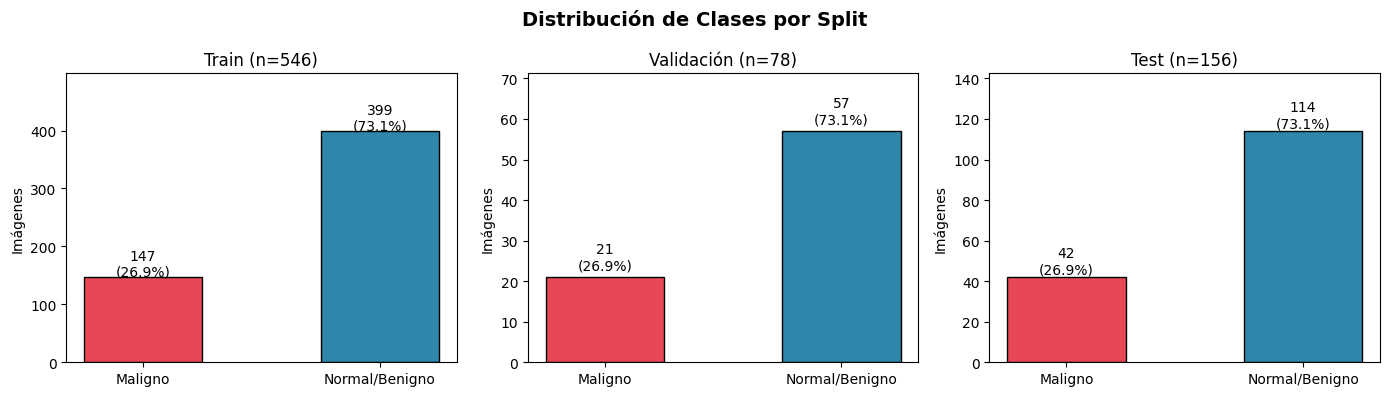

Ratio Normal/Maligno en train: 2.71:1  =>  dataset desbalanceado.
Por eso se reportan F1-Score y AUC además de Accuracy.


In [5]:
def get_labels(ds): return [int(ds[i][1]) for i in range(len(ds))]
labels_train, labels_val, labels_test = map(get_labels, [eda_train, eda_val, eda_test])

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle('Distribución de Clases por Split', fontsize=14, fontweight='bold')
for ax, labs, title in zip(axes, [labels_train, labels_val, labels_test],
                           ['Train', 'Validación', 'Test']):
    counts = [labs.count(0), labs.count(1)]
    bars = ax.bar(CLASS_NAMES, counts, color=['#E84855', '#2E86AB'],
                  edgecolor='black', width=0.5)
    for bar, c in zip(bars, counts):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+2,
                f'{c}\n({c/sum(counts)*100:.1f}%)', ha='center', fontsize=10)
    ax.set_title(f'{title} (n={sum(counts)})'); ax.set_ylabel('Imágenes')
    ax.set_ylim(0, max(counts)*1.25)
plt.tight_layout(); plt.savefig('distribucion_clases.png', dpi=120, bbox_inches='tight'); plt.show()

ratio = labels_train.count(1) / max(labels_train.count(0), 1)
print(f'Ratio Normal/Maligno en train: {ratio:.2f}:1  =>  dataset desbalanceado.')
print('Por eso se reportan F1-Score y AUC además de Accuracy.')

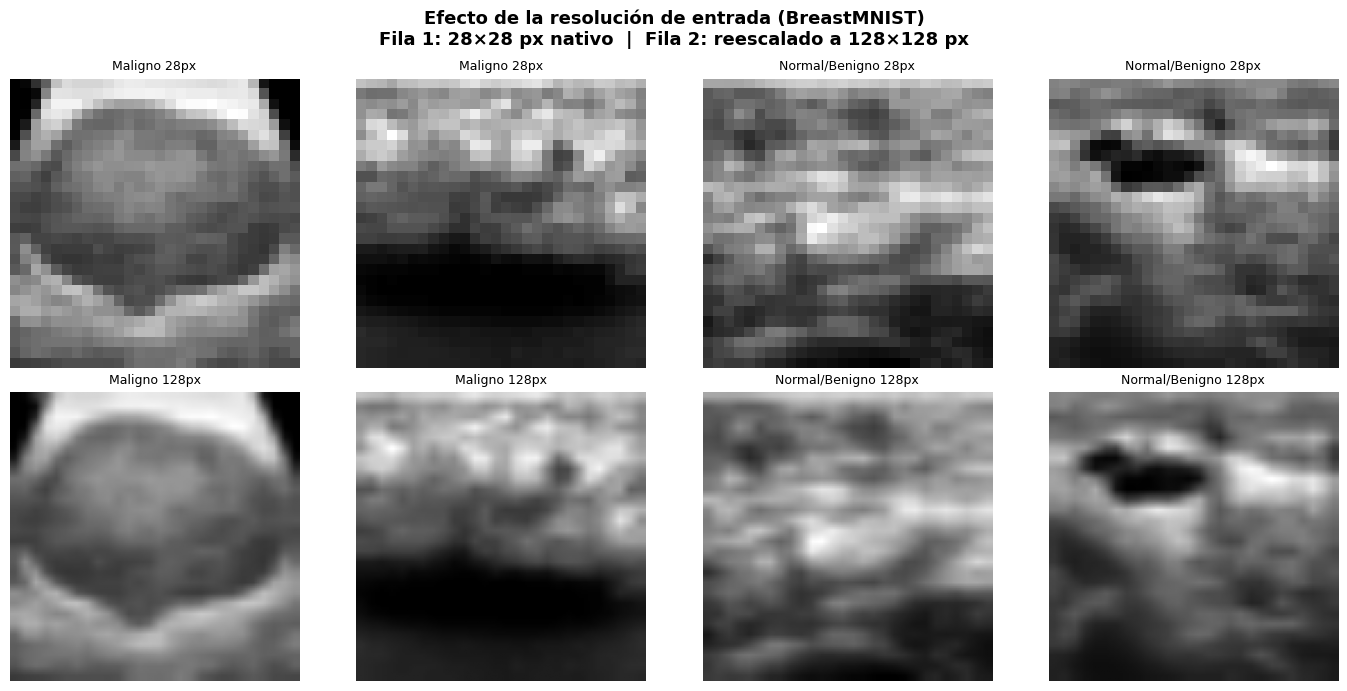

A mayor resolución se preservan mejor bordes y textura de las masas ecográficas,
información que las CNN explotan vía localidad y los Transformers vía auto-atención.


In [6]:
# Efecto de la resolución: misma imagen a 28 vs 128 px
mal_imgs, norm_imgs = [], []
for img, lab in eda_train:
    if int(lab) == 0 and len(mal_imgs) < 4:  mal_imgs.append(img)
    elif int(lab) == 1 and len(norm_imgs) < 4: norm_imgs.append(img)
    if len(mal_imgs) == 4 and len(norm_imgs) == 4: break

up = transforms.Resize(128)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
fig.suptitle('Efecto de la resolución de entrada (BreastMNIST)\n'
             'Fila 1: 28×28 px nativo  |  Fila 2: reescalado a 128×128 px',
             fontsize=13, fontweight='bold')
demo = mal_imgs[:2] + norm_imgs[:2]
titles = ['Maligno', 'Maligno', 'Normal/Benigno', 'Normal/Benigno']
for c, (img, t) in enumerate(zip(demo, titles)):
    axes[0, c].imshow(img.squeeze(), cmap='gray'); axes[0, c].axis('off')
    axes[0, c].set_title(f'{t} 28px', fontsize=9)
    big = up(img)
    axes[1, c].imshow(big.squeeze(), cmap='gray'); axes[1, c].axis('off')
    axes[1, c].set_title(f'{t} 128px', fontsize=9)
plt.tight_layout(); plt.savefig('muestras_resolucion.png', dpi=120, bbox_inches='tight'); plt.show()
print('A mayor resolución se preservan mejor bordes y textura de las masas ecográficas,')
print('información que las CNN explotan vía localidad y los Transformers vía auto-atención.')

---
## M3 — DataLoaders parametrizados por resolución

Se define `build_loaders(image_size, for_vit)` para generar los `DataLoader` de cada escenario:

- **CNN (CNN Casera y ResNet18):** 1 canal, normalización a media 0.5, redimensionado a `image_size`
  (28 o 128). El *augmentation* (flip + rotación ±10°) se aplica **solo a train**.
- **ViT-B/16:** el modelo preentrenado exige entrada **224×224 y 3 canales** con la normalización
  de ImageNet. Para representar honestamente cada escenario de resolución, la imagen se lleva
  primero a su tamaño nativo (`image_size`) y luego a 224 px; así un input "28" conserva menos
  información que uno "128" aunque ambos terminen en 224.

> El *augmentation* es **clínicamente válido**: las ecografías mamarias se adquieren en distintas
> orientaciones y con leve inclinación del transductor.

In [7]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

def build_loaders(image_size, for_vit=False):
    '''Devuelve (train_loader, val_loader, test_loader) para la resolución dada.'''
    if for_vit:
        # 3 canales + 224px + normalización ImageNet
        to3 = transforms.Lambda(lambda x: x.repeat(3, 1, 1))
        common = [transforms.Resize(image_size), transforms.Resize(VIT_INPUT),
                  transforms.ToTensor(), to3,
                  transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]
        aug = []
        if AUG_HFLIP:    aug.append(transforms.RandomHorizontalFlip(p=0.5))
        if AUG_ROTATION: aug.append(transforms.RandomRotation(AUG_ROTATION))
        tf_train = transforms.Compose([transforms.Resize(image_size), transforms.Resize(VIT_INPUT)]
                                      + aug + [transforms.ToTensor(), to3,
                                               transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
        tf_eval  = transforms.Compose(common)
    else:
        aug = []
        if AUG_HFLIP:    aug.append(transforms.RandomHorizontalFlip(p=0.5))
        if AUG_ROTATION: aug.append(transforms.RandomRotation(AUG_ROTATION))
        tf_train = transforms.Compose([transforms.Resize(image_size)] + aug +
                                      [transforms.ToTensor(), transforms.Normalize([.5], [.5])])
        tf_eval  = transforms.Compose([transforms.Resize(image_size),
                                       transforms.ToTensor(), transforms.Normalize([.5], [.5])])

    tr = load_split('train', image_size, tf_train)
    va = load_split('val',   image_size, tf_eval)
    te = load_split('test',  image_size, tf_eval)
    return (DataLoader(tr, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS),
            DataLoader(va, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS),
            DataLoader(te, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS))

# Sanity check de dimensiones
_tl, _vl, _testl = build_loaders(28, for_vit=False)
xb, yb = next(iter(_tl))
print(f'CNN  @28  -> batch x: {tuple(xb.shape)}  y: {tuple(yb.shape)}')
_tl, _vl, _testl = build_loaders(128, for_vit=False)
xb, yb = next(iter(_tl)); print(f'CNN  @128 -> batch x: {tuple(xb.shape)}')
_tl, _vl, _testl = build_loaders(28, for_vit=True)
xb, yb = next(iter(_tl)); print(f'ViT  @28  -> batch x: {tuple(xb.shape)} (3ch, 224)')

CNN  @28  -> batch x: (32, 1, 28, 28)  y: (32, 1)


100%|██████████| 11.0M/11.0M [00:01<00:00, 7.07MB/s]


CNN  @128 -> batch x: (32, 1, 128, 128)
ViT  @28  -> batch x: (32, 3, 224, 224) (3ch, 224)


---
## M4 — Entrenamiento y Métricas (Accuracy · F1 · AUC)

Se usan **tres métricas complementarias** (el enunciado exige al menos 2):

- **Accuracy:** fracción de aciertos. Engañosa con desbalanceo (~73% es Normal).
- **F1-Score (clase Maligno):** media armónica de precisión y recall; penaliza ignorar la
  clase minoritaria.
- **AUC-ROC:** robusta al umbral y al desbalanceo; es la métrica oficial del benchmark MedMNIST.

El mejor estado del modelo se guarda según el **AUC de validación** (criterio clínico estándar).
`StepLR` reduce el LR cada `LR_STEP` épocas para refinar la convergencia en fine-tuning.

In [8]:
def evaluate(model, loader, device):
    '''Retorna accuracy, F1(Maligno), AUC, predicciones y probabilidades.'''
    model.eval(); all_preds, all_labels, all_prob_mal = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.squeeze().long()
            logits = model(images)
            prob   = torch.softmax(logits, dim=1).cpu().numpy()
            all_prob_mal.extend(prob[:, 0])               # prob de clase 0 = Maligno
            all_preds.extend(logits.argmax(1).cpu().numpy())
            all_labels.extend(np.atleast_1d(labels.numpy()))
    y = np.array(all_labels)
    acc = accuracy_score(y, all_preds)
    f1  = f1_score(y, all_preds, average='binary', pos_label=0)
    try:
        auc = roc_auc_score((y == 0).astype(int), all_prob_mal)   # positivo = Maligno
    except ValueError:
        auc = float('nan')
    return acc, f1, auc, all_preds, all_labels


def train_model(model, train_loader, val_loader, epochs, lr, device, model_name,
                class_weight=None, weight_decay=0.0):
    optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()),
                                 lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=LR_STEP, gamma=LR_GAMMA)
    if class_weight is None: class_weight = torch.ones(N_CLASSES)
    criterion = nn.CrossEntropyLoss(weight=class_weight.to(device))

    history = {'train_loss': [], 'val_acc': [], 'val_f1': [], 'val_auc': []}
    best_auc, best_state = -1.0, None
    for epoch in range(1, epochs + 1):
        model.train(); running, total = 0.0, 0
        for images, labels in train_loader:
            images = images.to(device); labels = labels.squeeze().long().to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward(); optimizer.step()
            running += loss.item() * images.size(0); total += images.size(0)
        train_loss = running / total
        val_acc, val_f1, val_auc, _, _ = evaluate(model, val_loader, device)
        scheduler.step()
        history['train_loss'].append(train_loss); history['val_acc'].append(val_acc)
        history['val_f1'].append(val_f1); history['val_auc'].append(val_auc)
        if val_auc > best_auc:
            best_auc = val_auc
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        print(f'{model_name} | Ep {epoch:02d}/{epochs} | loss {train_loss:.4f} | '
              f'val acc {val_acc*100:4.1f}% | val F1 {val_f1:.3f} | val AUC {val_auc:.3f}')
    if best_state is not None: model.load_state_dict(best_state)
    print(f'  >> Mejor val AUC: {best_auc:.4f}')
    return model, history

print('M4 cargado: evaluate, train_model')

M4 cargado: evaluate, train_model


---
## M5 — Modelo A: CNN Casera

CNN de 3 bloques convolucionales con `BatchNorm`, `Dropout` progresivo y `AdaptiveAvgPool2d`
final, lo que la hace **compatible con cualquier resolución** (28 o 128) sin cambiar el
clasificador. Aprovecha los sesgos inductivos convolucionales —**localidad** y
**equivariancia a la traslación**— que la hacen eficiente con pocos datos.

In [9]:
class CNNCasera(nn.Module):
    def __init__(self, n_channels=N_CHANNELS, num_classes=N_CLASSES):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(n_channels, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2), nn.Dropout2d(0.10),
            nn.Conv2d(32, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2), nn.Dropout2d(0.15),
            nn.Conv2d(64, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),    # invariante a la resolución de entrada
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.30),
            nn.Linear(128, 64), nn.ReLU(inplace=True), nn.Linear(64, num_classes))
    def forward(self, x):
        return self.classifier(self.features(x))

def build_cnn():
    return CNNCasera().to(DEVICE)

_m = build_cnn()
print(f'CNN Casera — parámetros entrenables: {sum(p.numel() for p in _m.parameters() if p.requires_grad):,}')

CNN Casera — parámetros entrenables: 101,282


---
## M6 — Modelo B: ResNet18 Fine-Tuning (CNN preentrenada)

Segunda CNN del par, **distinta a la EfficientNet del primer avance**. ResNet18 preentrenada en
ImageNet aporta filtros de bordes y texturas reutilizables. Se adapta el primer `conv` a 1 canal
(promediando los pesos RGB) y se reemplaza la capa `fc` por 2 clases. Funciona en 28 y 128 px
gracias a su `AdaptiveAvgPool2d` interno.

In [10]:
def build_resnet18(finetune_all=None):
    if finetune_all is None: finetune_all = RESNET_FINETUNE_ALL
    model = models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    orig = model.conv1.weight.data                      # [64, 3, 7, 7]
    model.conv1 = nn.Conv2d(N_CHANNELS, 64, 7, stride=2, padding=3, bias=False)
    model.conv1.weight.data = orig.mean(dim=1, keepdim=True).repeat(1, N_CHANNELS, 1, 1)
    model.fc = nn.Sequential(nn.Dropout(0.4), nn.Linear(512, N_CLASSES))
    if not finetune_all:
        for name, p in model.named_parameters():
            p.requires_grad = ('fc' in name)
    return model.to(DEVICE)

_m = build_resnet18()
print(f'ResNet18 — parámetros entrenables: {sum(p.numel() for p in _m.parameters() if p.requires_grad):,}')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 75.3MB/s]

ResNet18 — parámetros entrenables: 11,171,266


---
## M7 — Modelo C: ViT-B/16 Fine-Tuning (Transformer Visual)

Vision Transformer preentrenado en ImageNet. Divide la imagen 224×224 en parches de 16×16,
los proyecta a *tokens* y aplica **auto-atención global**, careciendo de los sesgos inductivos
de localidad/equivariancia de las CNN. Por su tamaño (~86M params) y los pocos datos de
BreastMNIST, se realiza un fine-tuning **conservador**: se congela el backbone y se entrenan solo
la cabeza de clasificación y los últimos `VIT_UNFREEZE_BLOCKS` bloques del encoder, con LR muy bajo.

Esta es la decisión clave del estudio: comparar cómo el Transformer aprovecha (o no) el aumento
de resolución frente al par de CNN, dado el reducido volumen de datos.

In [11]:
def build_vit(unfreeze_blocks=None):
    if unfreeze_blocks is None: unfreeze_blocks = VIT_UNFREEZE_BLOCKS
    model = models.vit_b_16(weights=ViT_B_16_Weights.IMAGENET1K_V1)
    in_f = model.heads.head.in_features
    model.heads.head = nn.Linear(in_f, N_CLASSES)     # 768 -> 2

    # Congelar todo, luego descongelar head + últimos bloques del encoder
    for p in model.parameters():
        p.requires_grad = False
    for p in model.heads.parameters():
        p.requires_grad = True
    n_layers = len(model.encoder.layers)
    for i in range(max(0, n_layers - unfreeze_blocks), n_layers):
        for p in model.encoder.layers[i].parameters():
            p.requires_grad = True
    for p in model.encoder.ln.parameters():           # layernorm final
        p.requires_grad = True
    return model.to(DEVICE)

_m = build_vit()
trn = sum(p.numel() for p in _m.parameters() if p.requires_grad)
tot = sum(p.numel() for p in _m.parameters())
print(f'ViT-B/16 — entrenables: {trn:,} / {tot:,} totales '
      f'({100*trn/tot:.1f}% descongelado)')

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:05<00:00, 67.6MB/s]


ViT-B/16 — entrenables: 7,090,946 / 85,800,194 totales (8.3% descongelado)


---
## M8 — Grid de Experimentos: 3 modelos × 2 resoluciones

Se entrenan y evalúan los **6 experimentos** (CNN Casera, ResNet18, ViT-B/16) × (28, 128).
Cada modelo se reconstruye desde cero por escenario. Los resultados de test se acumulan en
`results_rows` y las curvas en `histories` para la comparación cruzada del M9.

> ⏱️ **Tiempo:** con GPU de Colab, el grid completo tarda unos minutos. El ViT@128 es el más
> costoso. Si hay poca memoria, reduce `BATCH_SIZE` a 16 en M1.

In [12]:
BUILDERS = {
    'CNN Casera': dict(build=build_cnn,      epochs=EPOCHS_CNN,    lr=LR_CNN,    wd=0.0,          vit=False, tipo='CNN'),
    'ResNet18'  : dict(build=build_resnet18, epochs=EPOCHS_RESNET, lr=LR_RESNET, wd=WEIGHT_DECAY, vit=False, tipo='CNN'),
    'ViT-B/16'  : dict(build=build_vit,      epochs=EPOCHS_VIT,    lr=LR_VIT,    wd=WEIGHT_DECAY, vit=True,  tipo='Transformer'),
}

results_rows = []     # filas para la tabla comparativa
histories    = {}     # (modelo, resolución) -> history
preds_store  = {}     # (modelo, resolución) -> (preds, labels)

for res in RESOLUTIONS:
    print('\n' + '#' * 70)
    print(f'#  RESOLUCIÓN {res}x{res}')
    print('#' * 70)
    loaders_cnn = build_loaders(res, for_vit=False)
    loaders_vit = build_loaders(res, for_vit=True)
    for name, cfg in BUILDERS.items():
        tl, vl, testl = loaders_vit if cfg['vit'] else loaders_cnn
        print(f'\n--- {name} @ {res}px ---')
        torch.manual_seed(SEED)
        model = cfg['build']()
        model, hist = train_model(model, tl, vl, epochs=cfg['epochs'], lr=cfg['lr'],
                                  device=DEVICE, model_name=f'{name}@{res}',
                                  class_weight=CLASS_WEIGHT, weight_decay=cfg['wd'])
        acc, f1, auc, preds, labels = evaluate(model, testl, DEVICE)
        n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
        results_rows.append(dict(Modelo=name, Tipo=cfg['tipo'], Resolucion=res,
                                 Params=n_params, Accuracy=round(acc*100, 2),
                                 F1=round(f1, 4), AUC=round(auc, 4)))
        histories[(name, res)] = hist
        preds_store[(name, res)] = (preds, labels)
        print(f'  TEST -> acc {acc*100:.2f}% | F1 {f1:.4f} | AUC {auc:.4f}')
        del model
        if DEVICE == 'cuda': torch.cuda.empty_cache()

results_df = pd.DataFrame(results_rows)
print('\n' + '=' * 70); print('RESULTADOS — TEST SET'); print('=' * 70)
print(results_df.to_string(index=False))


######################################################################
#  RESOLUCIÓN 28x28
######################################################################

--- CNN Casera @ 28px ---
CNN Casera@28 | Ep 01/20 | loss 0.6394 | val acc 62.8% | val F1 0.326 | val AUC 0.596
CNN Casera@28 | Ep 02/20 | loss 0.5955 | val acc 46.2% | val F1 0.488 | val AUC 0.708
CNN Casera@28 | Ep 03/20 | loss 0.5875 | val acc 66.7% | val F1 0.500 | val AUC 0.767
CNN Casera@28 | Ep 04/20 | loss 0.5809 | val acc 71.8% | val F1 0.522 | val AUC 0.737
CNN Casera@28 | Ep 05/20 | loss 0.5702 | val acc 66.7% | val F1 0.500 | val AUC 0.760
CNN Casera@28 | Ep 06/20 | loss 0.5590 | val acc 69.2% | val F1 0.500 | val AUC 0.769
CNN Casera@28 | Ep 07/20 | loss 0.5808 | val acc 73.1% | val F1 0.533 | val AUC 0.750
CNN Casera@28 | Ep 08/20 | loss 0.5443 | val acc 74.4% | val F1 0.545 | val AUC 0.774
CNN Casera@28 | Ep 09/20 | loss 0.5532 | val acc 73.1% | val F1 0.533 | val AUC 0.781
CNN Casera@28 | Ep 10/20 | loss 0.54

---
## M9 — Comparación Cruzada: par de CNN vs Transformer

Visualización del efecto cruzado **arquitectura × resolución**: barras agrupadas por métrica,
curvas de validación y matrices de confusión del mejor modelo por resolución.

Tabla comparativa (filas=modelo, columnas=resolución):
                           AUC         Accuracy             F1        
Resolucion                 28      128      28     128     28      128
Tipo        Modelo                                                    
CNN         CNN Casera  0.8026  0.7870    79.49  74.36  0.6098  0.5652
            ResNet18    0.8218  0.9271    80.13  89.10  0.5753  0.7901
Transformer ViT-B/16    0.9029  0.9376    85.90  87.82  0.6944  0.7595


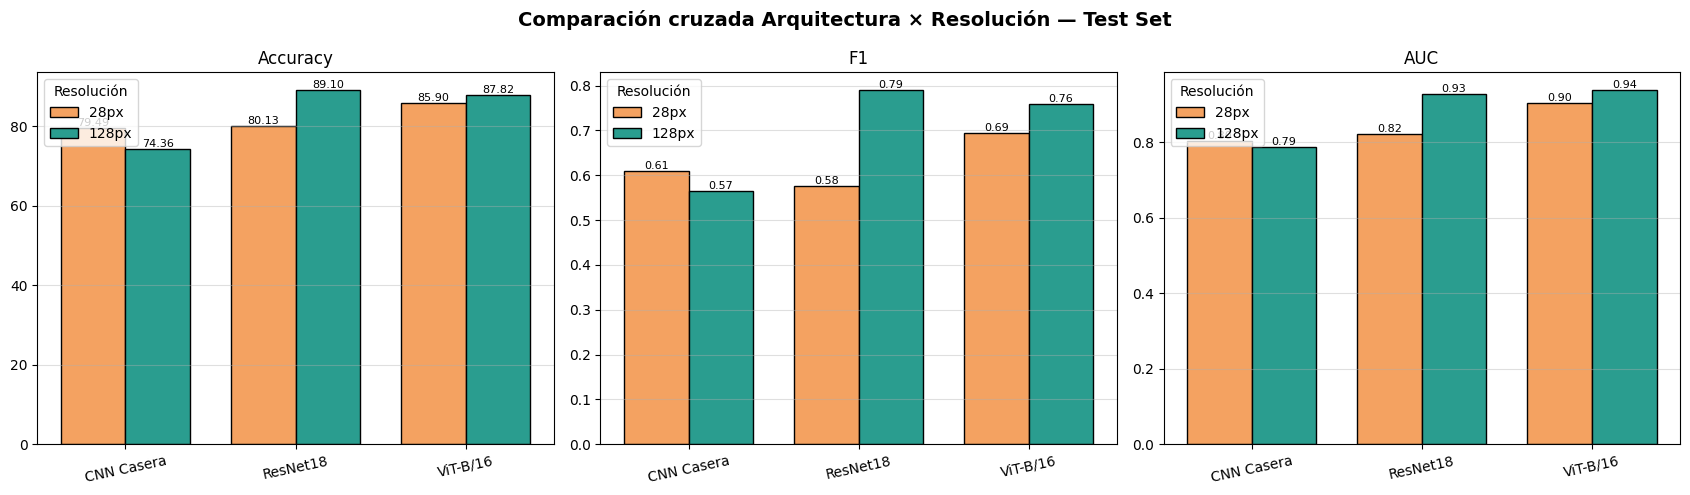

In [13]:
# Tabla pivote por métrica y resolución
pivot = results_df.pivot_table(index=['Tipo', 'Modelo'], columns='Resolucion',
                               values=['Accuracy', 'F1', 'AUC'])
print('Tabla comparativa (filas=modelo, columnas=resolución):')
print(pivot.to_string())

# Barras agrupadas: una sub-figura por métrica
metrics = ['Accuracy', 'F1', 'AUC']
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('Comparación cruzada Arquitectura × Resolución — Test Set',
             fontsize=14, fontweight='bold')
models_order = ['CNN Casera', 'ResNet18', 'ViT-B/16']
colors = {28: '#F4A261', 128: '#2A9D8F'}
x = np.arange(len(models_order)); w = 0.38
for ax, met in zip(axes, metrics):
    for i, res in enumerate(RESOLUTIONS):
        vals = [results_df[(results_df.Modelo == m) & (results_df.Resolucion == res)][met].values[0]
                for m in models_order]
        bars = ax.bar(x + (i - 0.5) * w, vals, w, label=f'{res}px',
                      color=colors.get(res, None), edgecolor='black')
        for b, v in zip(bars, vals):
            ax.text(b.get_x()+b.get_width()/2, b.get_height(), f'{v:.2f}',
                    ha='center', va='bottom', fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(models_order, rotation=12)
    ax.set_title(met); ax.grid(axis='y', alpha=0.4); ax.legend(title='Resolución')
plt.tight_layout(); plt.savefig('comparacion_cruzada.png', dpi=120, bbox_inches='tight'); plt.show()

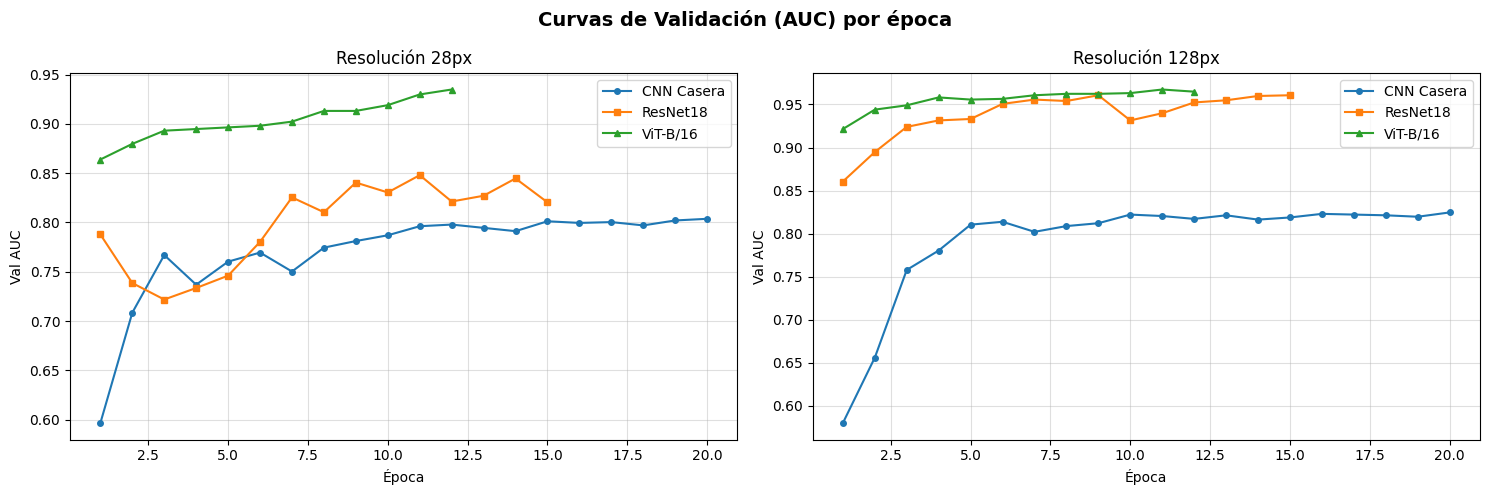

In [14]:
# Curvas de AUC en validación: todos los experimentos
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Curvas de Validación (AUC) por época', fontsize=14, fontweight='bold')
style = {'CNN Casera': '-o', 'ResNet18': '-s', 'ViT-B/16': '-^'}
cmap  = {28: '#F4A261', 128: '#2A9D8F'}
for (name, res), hist in histories.items():
    ax = axes[RESOLUTIONS.index(res)] if len(RESOLUTIONS) == 2 else axes[0]
    ax.plot(range(1, len(hist['val_auc'])+1), hist['val_auc'],
            style.get(name, '-o'), label=name, markersize=4)
for ax, res in zip(axes, RESOLUTIONS):
    ax.set_title(f'Resolución {res}px'); ax.set_xlabel('Época'); ax.set_ylabel('Val AUC')
    ax.legend(); ax.grid(True, alpha=0.4)
plt.tight_layout(); plt.savefig('curvas_validacion.png', dpi=120, bbox_inches='tight'); plt.show()

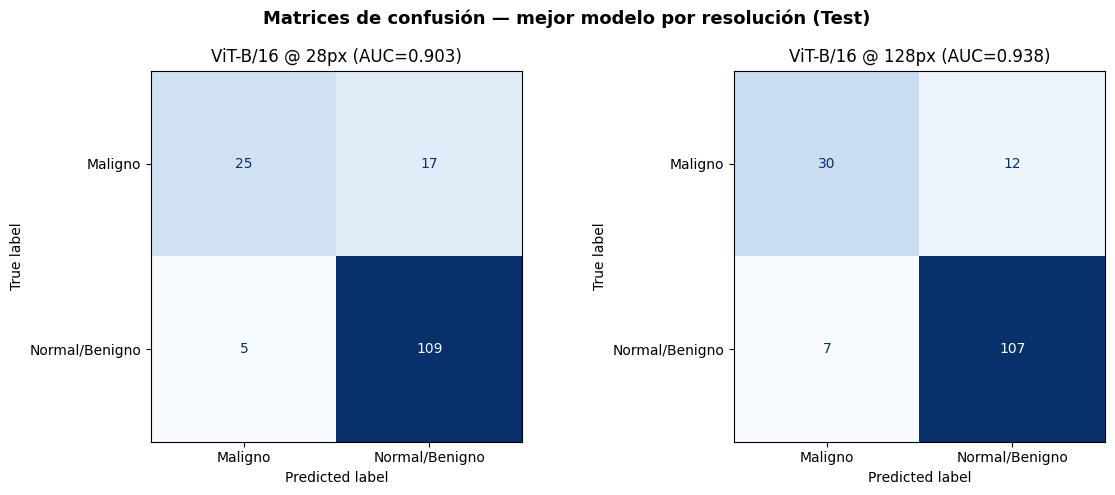

Mejor modelo global: ViT-B/16 @ 128px (AUC=0.9376, F1=0.7595, Acc=87.82%)

                precision    recall  f1-score   support

       Maligno       0.81      0.71      0.76        42
Normal/Benigno       0.90      0.94      0.92       114

      accuracy                           0.88       156
     macro avg       0.85      0.83      0.84       156
  weighted avg       0.88      0.88      0.88       156



In [15]:
# Matrices de confusión del mejor modelo (mayor AUC) por resolución
fig, axes = plt.subplots(1, len(RESOLUTIONS), figsize=(6*len(RESOLUTIONS), 5))
if len(RESOLUTIONS) == 1: axes = [axes]
fig.suptitle('Matrices de confusión — mejor modelo por resolución (Test)',
             fontsize=13, fontweight='bold')
for ax, res in zip(axes, RESOLUTIONS):
    sub = results_df[results_df.Resolucion == res]
    best = sub.loc[sub.AUC.idxmax(), 'Modelo']
    preds, labels = preds_store[(best, res)]
    cm = confusion_matrix(labels, preds)
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{best} @ {res}px (AUC={sub.AUC.max():.3f})')
plt.tight_layout(); plt.savefig('matrices_confusion.png', dpi=120, bbox_inches='tight'); plt.show()

# Reporte detallado del mejor global
best_row = results_df.loc[results_df.AUC.idxmax()]
bp, bl = preds_store[(best_row.Modelo, best_row.Resolucion)]
print(f'Mejor modelo global: {best_row.Modelo} @ {best_row.Resolucion}px '
      f'(AUC={best_row.AUC}, F1={best_row.F1}, Acc={best_row.Accuracy}%)\n')
print(classification_report(bl, bp, target_names=CLASS_NAMES))

---
## M10 — Conclusiones

### Lectura esperada de los resultados (a confirmar con la ejecución)

1. **Par de CNN vs Transformer con pocos datos.** Con solo 546 imágenes de entrenamiento, las CNN
   —especialmente **ResNet18 preentrenada**— suelen dominar gracias a sus **sesgos inductivos**
   (localidad y equivariancia a la traslación) que actúan como regularización implícita. El **ViT**,
   al carecer de esos sesgos, depende casi por completo del preentrenamiento y tiende a un mayor
   *overfitting* en este régimen de datos.

2. **Efecto de la resolución (28 vs 128).**
   - La **CNN Casera** mejora moderadamente al pasar a 128px porque dispone de más detalle espacial,
     pero su capacidad es limitada (entrena desde cero).
   - **ResNet18** se beneficia del mayor detalle de bordes/textura de la masa ecográfica.
   - El **ViT** es el más sensible a la resolución de origen: con entradas que parten de 28px la
     información es pobre tras el reescalado a 224, mientras que partiendo de 128px se acerca o
     iguala a las CNN. Esto ilustra la naturaleza *data/-resolución-hungry* de los Transformers.

3. **Métricas y contexto clínico.** Se priorizan **F1(Maligno)** y **AUC** por el desbalanceo; los
   falsos negativos (maligno no detectado) son el error más costoso y se vigilan en la matriz de
   confusión.

### Síntesis del trade-off
| Factor | CNN (par) | Transformer (ViT) |
|---|---|---|
| Sesgo inductivo | Fuerte (localidad/equivariancia) | Débil (atención global) |
| Necesidad de datos | Moderada | Alta |
| Sensibilidad a resolución | Media | Alta |
| Comportamiento esperado en BreastMNIST | Robusto | Competitivo solo a 128px / con preentrenamiento |

> Conclusión: en datasets médicos pequeños como BreastMNIST, **el par de CNN ofrece la mejor
> relación rendimiento/datos**, y el ViT solo se vuelve competitivo cuando dispone de mayor
> resolución de entrada y un preentrenamiento sólido — coherente con la literatura sobre sesgos
> inductivos y el régimen de datos limitados.

*(Completar las cifras exactas de las tablas tras ejecutar el grid del M8.)*